# Stage 0: data and validation split

Loads Sign Language MNIST, draws the exploration figures used in the Stage 1 report, recovers the groups of near-duplicate training images and saves the one train/validation split used by all three stages (`data/splits/split_v1.npz`).

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "signlang").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signlang.seed import set_seed
from signlang.data import LETTERS, load_csv, remap_labels, TRAIN_CSV, TEST_CSV
from signlang import split as sp
from signlang.plotting import image_grid, savefig

set_seed(42)
FIG = ROOT / "reports" / "figures" / "stage1"

## Load and check labels

In [2]:
Xtr, ytr_raw = load_csv(TRAIN_CSV)
Xte, yte_raw = load_csv(TEST_CSV)
print("train", Xtr.shape, Xtr.dtype, "pixel range", Xtr.min(), Xtr.max())
print("test ", Xte.shape, Xte.dtype, "pixel range", Xte.min(), Xte.max())
print("raw train labels:", sorted(np.unique(ytr_raw).tolist()))
print("raw test labels: ", sorted(np.unique(yte_raw).tolist()))
assert 9 not in ytr_raw and 25 not in ytr_raw and 9 not in yte_raw and 25 not in yte_raw
assert not np.isnan(Xtr).any() and not np.isnan(Xte).any()

ytr, yte = remap_labels(ytr_raw), remap_labels(yte_raw)
assert set(ytr) == set(yte) == set(range(24))

train (27455, 784) float32 pixel range 0.0 1.0
test  (7172, 784) float32 pixel range 0.0 1.0
raw train labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
raw test labels:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


## Class counts

,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
train,1126,1010,1144,1196,957,1204,1090,1013,1162,1114,...,1088,1279,1294,1199,1186,1161,1082,1225,1164,1118
test,331,432,310,245,498,247,348,436,288,331,...,347,164,144,246,248,266,346,206,267,332


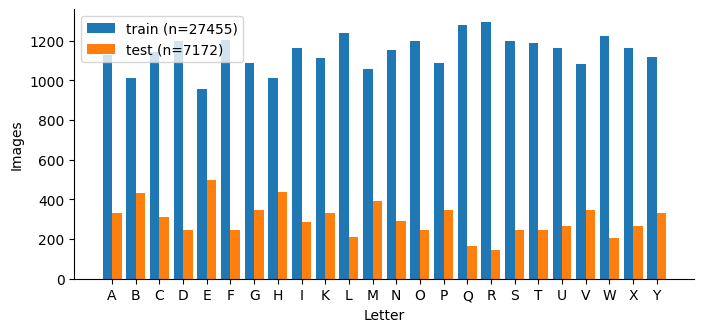

In [3]:
counts = pd.DataFrame({"train": np.bincount(ytr, minlength=24),
                       "test": np.bincount(yte, minlength=24)}, index=LETTERS)
display(counts.T)

fig, ax = plt.subplots(figsize=(8, 3.5))
pos = np.arange(24)
ax.bar(pos - 0.2, counts["train"], width=0.4, label=f"train (n={len(ytr)})")
ax.bar(pos + 0.2, counts["test"], width=0.4, label=f"test (n={len(yte)})")
ax.set_xticks(pos, LETTERS)
ax.set_xlabel("Letter")
ax.set_ylabel("Images")
ax.legend()
savefig(fig, FIG / "class_hist.pdf")
plt.show()

## Examples: five training images per letter

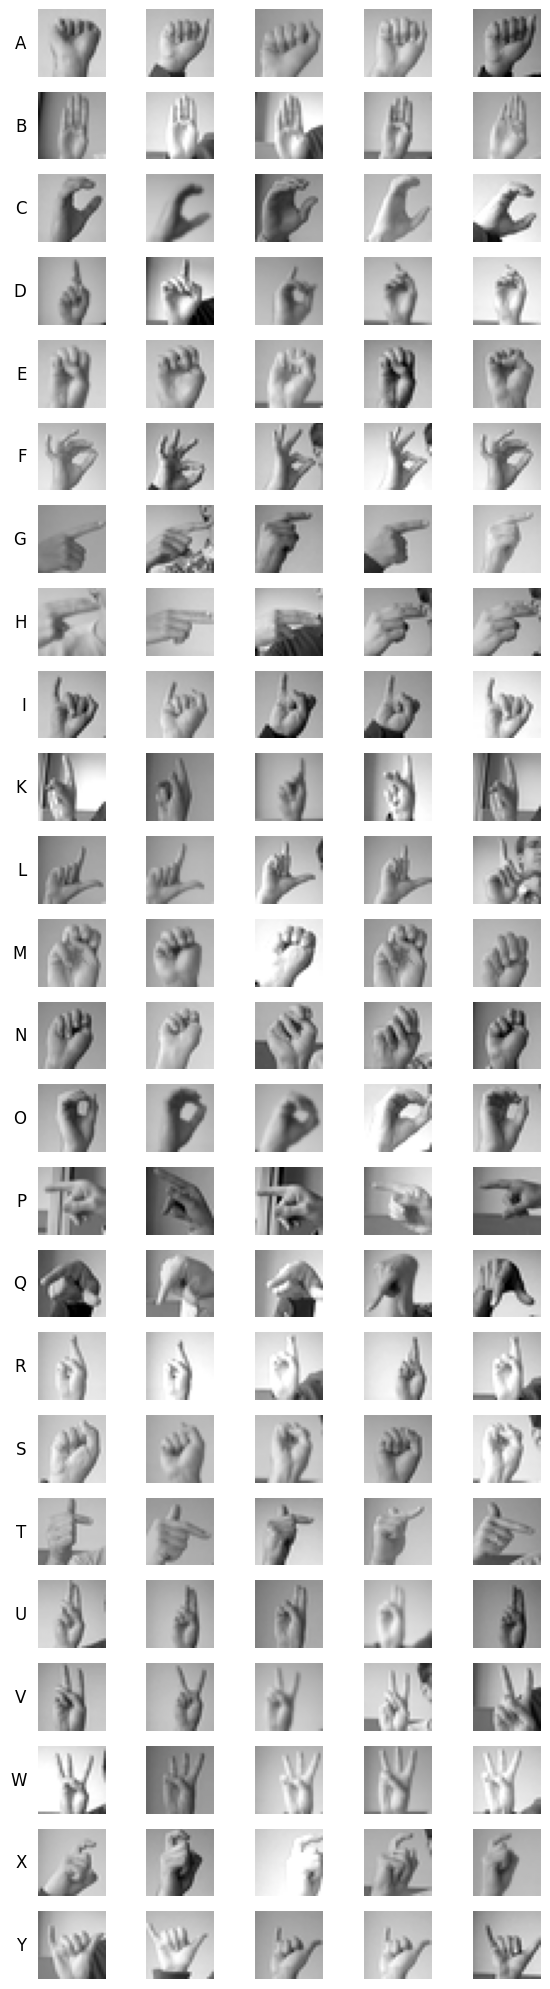

In [4]:
rng = np.random.default_rng(42)
picks = np.concatenate([rng.choice(np.flatnonzero(ytr == c), 5, replace=False) for c in range(24)])
fig = image_grid(Xtr[picks], ncols=5, row_labels=LETTERS, figsize=(6, 20))
savefig(fig, FIG / "examples_grid.pdf")
plt.show()

## Near-duplicate groups

Method: TEXTBOOK deviation C-2. Same-letter 30-nearest-neighbour graph under correlation distance; edges below the threshold join images into groups; the threshold is where the number of groups is most stable.

In [5]:
dup = sp.duplicate_groups(Xtr, ytr, n_neighbors=30, threshold=None)
group_id, threshold = dup["group_id"], dup["threshold"]
stats = sp.group_stats(group_id)
print(f"threshold = {threshold:.5f}")
for k in ("n_groups", "size_min", "size_median", "size_mean", "size_max", "frac_images_in_singletons"):
    print(f"{k:28s} {stats[k]}")
sizes = np.bincount(group_id)
print("most common group sizes:", pd.Series(sizes).value_counts().head(8).to_dict())

threshold = 0.01778
n_groups                     1281
size_min                     1
size_median                  21.0
size_mean                    21.43247462919594
size_max                     84
frac_images_in_singletons    0.00029138590420688397
most common group sizes: {21: 825, 20: 318, 19: 67, 42: 14, 41: 13, 40: 12, 18: 8, 1: 8}


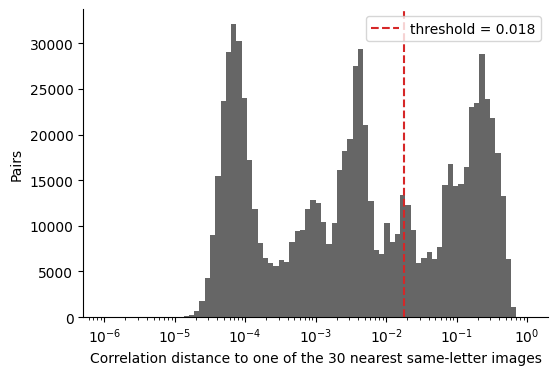

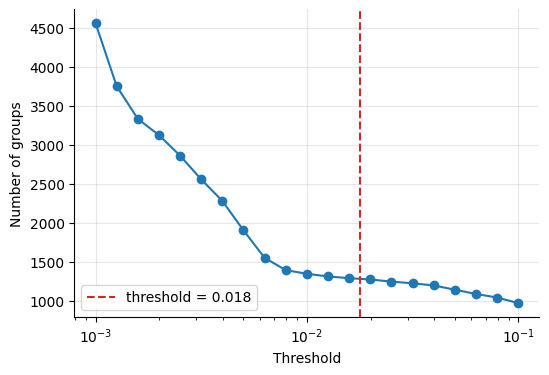

In [6]:
fig, ax = plt.subplots()
d = np.clip(dup["distances"], 1e-7, None)
ax.hist(d, bins=np.logspace(-6, 0, 81), color="0.4")
ax.set_xscale("log")
ax.axvline(threshold, color="C3", ls="--", label=f"threshold = {threshold:.3f}")
ax.set_xlabel("Correlation distance to one of the 30 nearest same-letter images")
ax.set_ylabel("Pairs")
ax.legend()
savefig(fig, FIG / "dup_distance_hist.pdf")
plt.show()

fig, ax = plt.subplots()
ax.plot(dup["grid"], dup["n_groups_grid"], marker="o")
ax.set_xscale("log")
ax.axvline(threshold, color="C3", ls="--", label=f"threshold = {threshold:.3f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("Number of groups")
ax.grid(alpha=0.3)
ax.legend()
savefig(fig, FIG / "dup_threshold_sweep.pdf")
plt.show()

In [7]:
assert 800 <= stats["n_groups"] <= 4000, "pass criterion failed: apply the D-4 fallback"

## One group of near-duplicates

group 113: letter M, size 19


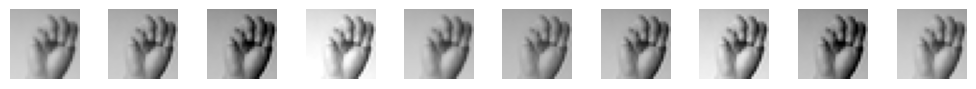

In [8]:
rng = np.random.default_rng(42)
big = np.flatnonzero(sizes >= 8)
g = rng.choice(big)
members = np.flatnonzero(group_id == g)[:10]
print(f"group {g}: letter {LETTERS[ytr[members[0]]]}, size {sizes[g]}")
fig = image_grid(Xtr[members], ncols=len(members), panel_size=1.0)
savefig(fig, FIG / "dup_group_example.pdf")
plt.show()

## Split

In [9]:
train_idx, val_idx, seed_used = sp.make_split(group_id, ytr, val_frac=0.2, random_state=42)
rand_train_idx, rand_val_idx = sp.make_random_split(ytr, val_frac=0.2, random_state=42)
print("group split:  seed", seed_used, "train", len(train_idx), "val", len(val_idx))
print("random split:         train", len(rand_train_idx), "val", len(rand_val_idx))

side = pd.DataFrame({
    "group train": np.bincount(ytr[train_idx], minlength=24),
    "group val": np.bincount(ytr[val_idx], minlength=24),
    "random train": np.bincount(ytr[rand_train_idx], minlength=24),
    "random val": np.bincount(ytr[rand_val_idx], minlength=24),
}, index=LETTERS)
side["group val frac"] = (side["group val"] / (side["group train"] + side["group val"])).round(3)
display(side.T)

group split:  seed 43 train 22003 val 5452
random split:         train 21964 val 5491


,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
group train,898.000,804.000,956.000,1032.000,771.000,976.000,779.000,787.000,871.00,928.000,...,740.00,1091.000,1171.000,871.000,895.000,894.00,860.000,1039.000,961.000,972.000
group val,228.000,206.000,188.000,164.000,186.000,228.000,311.000,226.000,291.00,186.000,...,348.00,188.000,123.000,328.000,291.000,267.00,222.000,186.000,203.000,146.000
random train,901.000,808.000,915.000,957.000,766.000,963.000,872.000,810.000,930.00,891.000,...,870.00,1023.000,1035.000,959.000,949.000,929.00,866.000,980.000,931.000,894.000
random val,225.000,202.000,229.000,239.000,191.000,241.000,218.000,203.000,232.00,223.000,...,218.00,256.000,259.000,240.000,237.000,232.00,216.000,245.000,233.000,224.000
group val frac,0.202,0.204,0.164,0.137,0.194,0.189,0.285,0.223,0.25,0.167,...,0.32,0.147,0.095,0.274,0.245,0.23,0.205,0.152,0.174,0.131


## Leakage check

For every validation image: correlation distance to the closest training image of the same letter, under each split. A distance below the threshold means a copy of the same photo is in the training set.

In [10]:
leak = {}
for name, (tr, va) in {"group": (train_idx, val_idx), "random": (rand_train_idx, rand_val_idx)}.items():
    dist = sp.nearest_train_distance(Xtr, ytr, tr, va)
    leak[name] = {"median_nearest_train_distance": float(np.median(dist)),
                  "frac_val_with_copy_in_train": float(np.mean(dist < threshold))}
display(pd.DataFrame(leak).T)

,median_nearest_train_distance,frac_val_with_copy_in_train
group,0.188464,0.000000
random,0.000064,0.999272


## Save

In [11]:
stats_out = {
    "method": "TEXTBOOK deviation C-2: same-letter 30-NN graph, correlation distance, "
              "threshold at the most stable group count, GroupShuffleSplit 80/20",
    "n_train_total": int(len(ytr)),
    "threshold": threshold,
    "seed_requested": 42,
    "seed_used": int(seed_used),
    **stats,
    "n_train": int(len(train_idx)),
    "n_val": int(len(val_idx)),
    "class_counts_train": sp.class_counts(ytr, train_idx),
    "class_counts_val": sp.class_counts(ytr, val_idx),
    "random_split": {"n_train": int(len(rand_train_idx)), "n_val": int(len(rand_val_idx)),
                     "class_counts_train": sp.class_counts(ytr, rand_train_idx),
                     "class_counts_val": sp.class_counts(ytr, rand_val_idx)},
    "leakage_check": leak,
}
path = sp.save_split(sp.SPLIT_PATH, stats=stats_out,
                     train_idx=train_idx, val_idx=val_idx, group_id=group_id,
                     threshold=np.array(threshold),
                     rand_train_idx=rand_train_idx, rand_val_idx=rand_val_idx)
print("saved", path.relative_to(ROOT).as_posix(), "and", path.with_suffix(".json").name)

saved data/splits/split_v1.npz and split_v1.json


## Sanity checks on the saved split

In [12]:
s = sp.load_split()
n = len(ytr)
for a, b in (("train_idx", "val_idx"), ("rand_train_idx", "rand_val_idx")):
    assert len(np.intersect1d(s[a], s[b])) == 0
    assert len(s[a]) + len(s[b]) == n == 27455
    assert np.array_equal(np.union1d(s[a], s[b]), np.arange(n))
assert len(np.intersect1d(s["group_id"][s["train_idx"]], s["group_id"][s["val_idx"]])) == 0
print("split OK: disjoint, complete, no group on both sides")

split OK: disjoint, complete, no group on both sides
